<a href="https://colab.research.google.com/github/Tj-pi/Credit-Card-Default-Prediction/blob/main/Credit_Card_Default_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install ucimlrepo

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Load the UCI Credit Card Default dataset
dataset = fetch_ucirepo(id=350)

# Combine features and target variable
df = dataset.data.features.copy()
df["default"] = dataset.data.targets.iloc[:, 0].values

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (30000, 24)

First 5 Rows:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0



Column Names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'default']


In [4]:

# Rename columns for easier analysis
column_names = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "default"
]

df.columns = column_names

print("Updated Column Names:")
print(df.columns.tolist())

display(df.head())


Updated Column Names:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default']


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:

# Step 3: Data Quality Checks

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check dataset dimensions
print("\nDataset Shape:", df.shape)


Missing Values:
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64

Duplicate Rows: 35

Data Types:
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
default      int64
dtype: object

Dataset Shape: (30000, 24)


Default Distribution:
default
0    23364
1     6636
Name: count, dtype: int64

Default Percentages:
default
0    77.88
1    22.12
Name: count, dtype: float64


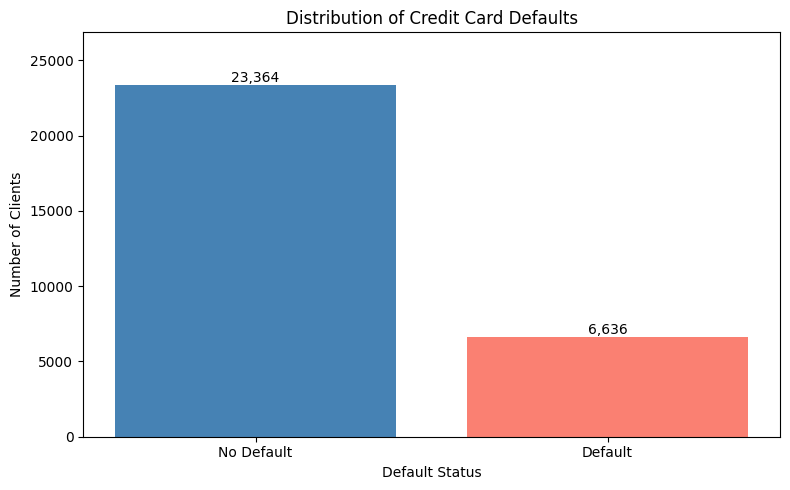

In [6]:

# Step 4: Distribution of Credit Card Defaults

import matplotlib.pyplot as plt

# Count clients in each category
default_counts = df["default"].value_counts().sort_index()

# Calculate percentages
default_percent = (default_counts / len(df)) * 100

print("Default Distribution:")
print(default_counts)

print("\nDefault Percentages:")
print(default_percent.round(2))

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["No Default", "Default"],
    default_counts.values,
    color=["steelblue", "salmon"]
)

# Add counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 200,
        f"{int(height):,}",
        ha="center"
    )

plt.title("Distribution of Credit Card Defaults")
plt.xlabel("Default Status")
plt.ylabel("Number of Clients")
plt.ylim(0, max(default_counts.values) * 1.15)
plt.tight_layout()
plt.show()


Default Rate by PAY_0:
PAY_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: default, dtype: float64


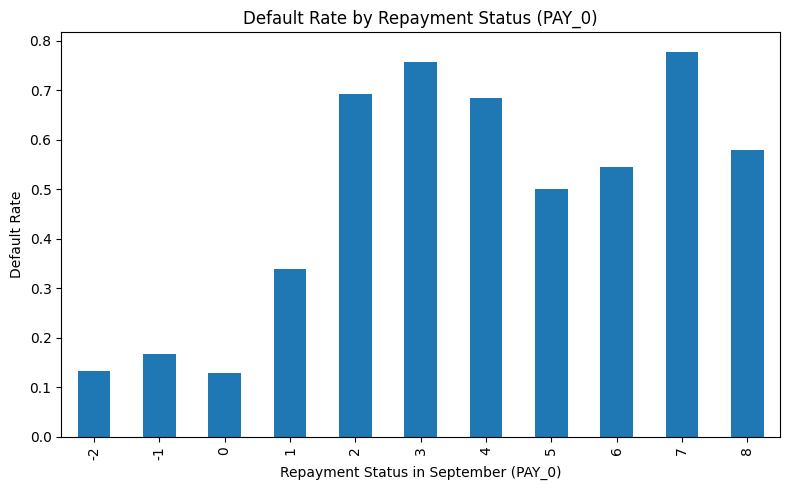

In [7]:
# Step 5: Default rate by repayment status (PAY_0)

default_by_pay0 = df.groupby("PAY_0")["default"].mean().sort_index()

print("Default Rate by PAY_0:")
print((default_by_pay0 * 100).round(2))

plt.figure(figsize=(8,5))
default_by_pay0.plot(kind="bar")

plt.title("Default Rate by Repayment Status (PAY_0)")
plt.xlabel("Repayment Status in September (PAY_0)")
plt.ylabel("Default Rate")
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

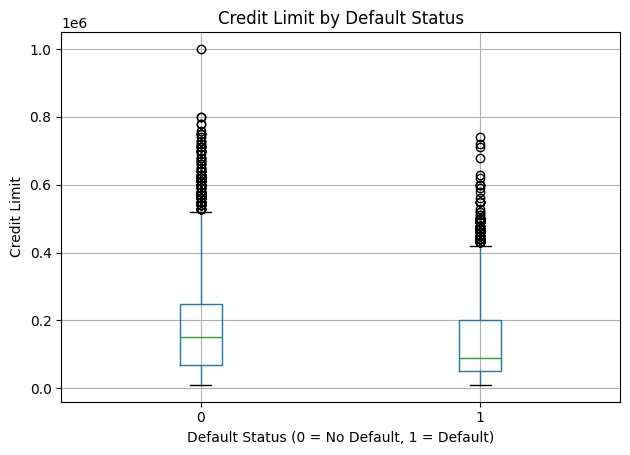

           count           mean            std      min      25%       50%  \
default                                                                      
0        23364.0  178099.726074  131628.359660  10000.0  70000.0  150000.0   
1         6636.0  130109.656420  115378.540571  10000.0  50000.0   90000.0   

              75%        max  
default                       
0        250000.0  1000000.0  
1        200000.0   740000.0  


In [8]:
# Step 6: Credit limit by default status

plt.figure(figsize=(8,5))
df.boxplot(column="LIMIT_BAL", by="default")

plt.title("Credit Limit by Default Status")
plt.suptitle("")  # removes extra automatic title
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Credit Limit")
plt.tight_layout()
plt.show()

# Summary statistics
print(df.groupby("default")["LIMIT_BAL"].describe())

Default Rate by Age Group:


,count,default_rate
AGE_GROUP,,
21-30,11013,22.44
31-40,10713,20.43
41-50,6005,23.30
51-60,1997,25.24
61+,272,26.84


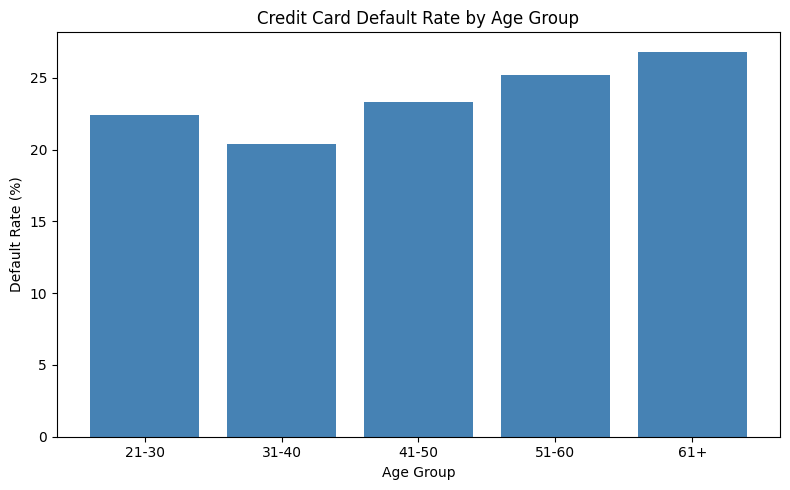

In [9]:

# Step 7: Default Rate by Age Group

# Create age groups
df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 100],
    labels=["21-30", "31-40", "41-50", "51-60", "61+"]
)

# Calculate default rate for each age group
age_default = (
    df.groupby("AGE_GROUP", observed=True)["default"]
    .agg(["count", "mean"])
)

age_default["default_rate"] = (
    age_default["mean"] * 100
)

print("Default Rate by Age Group:")
display(age_default[["count", "default_rate"]].round(2))

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    age_default.index.astype(str),
    age_default["default_rate"],
    color="steelblue"
)

plt.title("Credit Card Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


In [11]:

# Step 8: Train-Test Split

from sklearn.model_selection import train_test_split

# Separate predictor variables and target
X = df.drop(columns=["default", "AGE_GROUP"])
y = df["default"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Default Rate:",
      round(y_train.mean() * 100, 2), "%")

print("Testing Default Rate:",
      round(y_test.mean() * 100, 2), "%")


Training Data Shape: (22500, 23)
Testing Data Shape: (7500, 23)

Training Default Rate: 22.12 %
Testing Default Rate: 22.12 %
